# GenVerOpt reproduction — Stage 3a: environment, config, MM-IQ inspection
Paper: *Can machines reason non-verbally?* (arXiv 2610.13925v1).

**Scope of this notebook:** inspect the runtime, set up configuration, download MM-IQ and **print its real schema**.
No model code yet — the loader and splits are written after we see the actual columns.

**Status:** generated, not yet executed in Colab. Treat every cell as untested until you run it.

**Mode:** `quick` (subset, debugging) vs `repro` (paper-aligned splits). Quick-mode results are never reproduction results.

## 1. Environment inspection

In [ ]:
import sys, platform, shutil, os
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
try:
    import torch
    print("PyTorch:", torch.__version__, "| CUDA runtime:", torch.version.cuda)
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        p = torch.cuda.get_device_properties(0)
        print("GPU:", p.name, "| memory (GB):", round(p.total_memory/1024**3, 2))
except ImportError:
    print("PyTorch not installed")
try:
    import psutil
    print("RAM (GB): total", round(psutil.virtual_memory().total/1024**3,1),
          "| available", round(psutil.virtual_memory().available/1024**3,1))
except ImportError:
    pass
total, used, free = shutil.disk_usage("/")
print("Disk free (GB):", round(free/1024**3, 1))

Python: 3.13.15
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu130 | CUDA runtime: 13.0
CUDA available: True
GPU: Tesla T4 | memory (GB): 14.56
RAM (GB): total 12.7 | available 11.0
Disk free (GB): 70.3


## 2. Dependencies
Only what is needed. PyTorch is left untouched.

In [ ]:
!pip -q install datasets pillow matplotlib
import datasets, PIL, matplotlib
print("datasets", datasets.__version__, "| Pillow", PIL.__version__, "| matplotlib", matplotlib.__version__)

datasets 4.8.5 | Pillow 11.3.0 | matplotlib 3.10.0


## 3. Configuration
Persistent storage: files under `/content` are lost on runtime reset. Set `USE_DRIVE = True` to keep artifacts on Google Drive.

In [ ]:
import random, numpy as np, torch
from dataclasses import dataclass, asdict

@dataclass
class Cfg:
    mode: str = "quick"            # "quick" | "repro"
    seed: int = 0
    use_drive: bool = False
    work_dir: str = "/content/genveropt"
    hf_dataset_id: str = "afdsafas/MMIQ"   # third-party HF mirror, UNVERIFIED against the official release
    quick_subset: int = 200

cfg = Cfg()
if cfg.use_drive:
    from google.colab import drive
    drive.mount("/content/drive")
    cfg.work_dir = "/content/drive/MyDrive/genveropt"
os.makedirs(cfg.work_dir, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(cfg.seed)
print(asdict(cfg))

{'mode': 'quick', 'seed': 0, 'use_drive': False, 'work_dir': '/content/genveropt', 'hf_dataset_id': 'afdsafas/MMIQ', 'quick_subset': 200}


## 4. Download MM-IQ and inspect schema
Known so far (from the MM-IQ paper, arXiv 2502.00698): 2,710 test items over 8 reasoning paradigms; a separate 4,776-item training set was added in v2.
**Open question:** the GenVerOpt paper's counts (395 / 102 / 355 / 32+379) must be matched to a specific split and category field. This cell only reveals what is available.
Official homepage: https://acechq.github.io/MMIQ-benchmark/

In [ ]:
from datasets import load_dataset
ds = load_dataset(cfg.hf_dataset_id)
print(ds)
for split, d in ds.items():
    print("\n==", split, "| rows:", len(d))
    print("features:", d.features)
    ex = d[0]
    print({k: (v if isinstance(v, (str, int, float)) else type(v).__name__) for k, v in ex.items()})

data/train_1.parquet: reconstructing file:   0%|          |  0.00B /  116MB            

data/train_1.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2710 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'problem', 'solution'],
        num_rows: 2710
    })
})

== train | rows: 2710
features: {'image': Image(mode=None, decode=True), 'problem': Value('string'), 'solution': Value('string')}
{'image': 'PngImageFile', 'problem': 'Choose the most appropriate option from the four given choices to fill in the question mark, so that it presents a certain regularity:', 'solution': '<answer> B </answer>'}


In [ ]:
# Category/answer distributions for any low-cardinality string/int columns
from collections import Counter
for split, d in ds.items():
    for col, feat in d.features.items():
        if getattr(feat, "dtype", None) in ("string", "int32", "int64"):
            vals = d[col]
            c = Counter(vals)
            if len(c) <= 20:
                print(split, col, dict(c))

train solution {'<answer> B </answer>': 690, '<answer> D </answer>': 684, '<answer> C </answer>': 696, '<answer> A </answer>': 640}


image columns: ['image']


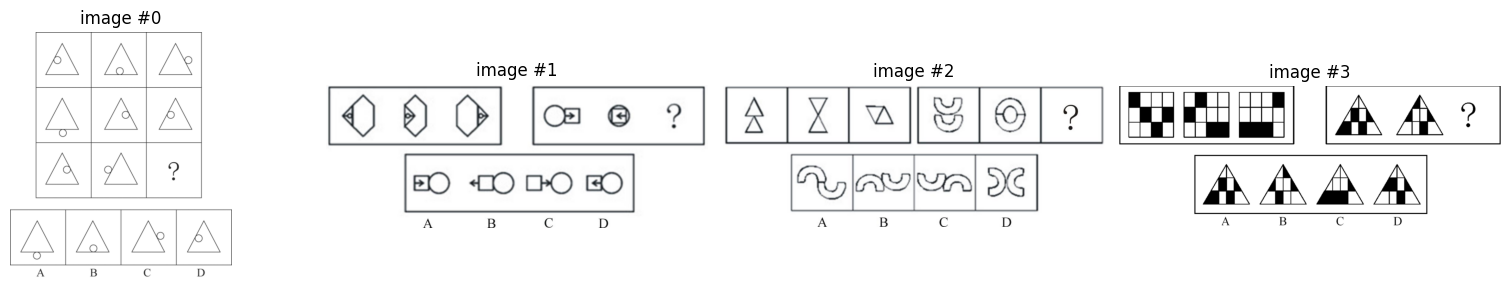

In [ ]:
# Save a few raw examples so we can eyeball the layout (how options are stored: one image or separate?)
import matplotlib.pyplot as plt
split = list(ds.keys())[0]
img_cols = [c for c, f in ds[split].features.items() if type(f).__name__ == "Image"]
print("image columns:", img_cols)
n = min(4, len(ds[split]))
fig, axes = plt.subplots(len(img_cols) or 1, n, figsize=(4*n, 3*(len(img_cols) or 1)), squeeze=False)
for j in range(n):
    for i, c in enumerate(img_cols):
        axes[i][j].imshow(ds[split][j][c]); axes[i][j].set_title(f"{c} #{j}"); axes[i][j].axis("off")
plt.tight_layout(); plt.savefig(f"{cfg.work_dir}/mmiq_examples.png", dpi=120); plt.show()

## Next
Run all cells and send back: the printed dataset structure, features, the distribution output, and the example image. From that I will write the split logic (matching Tab. 1 of the paper), the grid-with-candidate construction, and the dataset integrity checks.